In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset from the internet (no upload needed)
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

# Save an Excel copy for your submission
df.to_excel("WA_Fn-UseC_-Telco-Customer-Churn.xlsx", index=False)

print(df.head())
print("Shape:", df.shape)
print("Columns:", list(df.columns))
print(df.dtypes)
print(df.describe())

# Target variable
print(df["Churn"].value_counts())

# Important columns:
# tenure         = how many months the customer stayed
# Contract       = type of plan (month-to-month, 1 year, 2 year)
# MonthlyCharges = bill per month
# TotalCharges   = total paid so far
# Churn          = Yes (left) or No (stayed)  <-- target

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [7]:
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

# TotalCharges is text, so convert it to numbers
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Blank values are new customers (tenure = 0), so fill with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# customerID is only a label, it does not help prediction
df = df.drop("customerID", axis=1)

df = df.drop_duplicates()
print(df.shape)
print(df.dtypes)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Duplicates: 0
(7021, 20)
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      floa

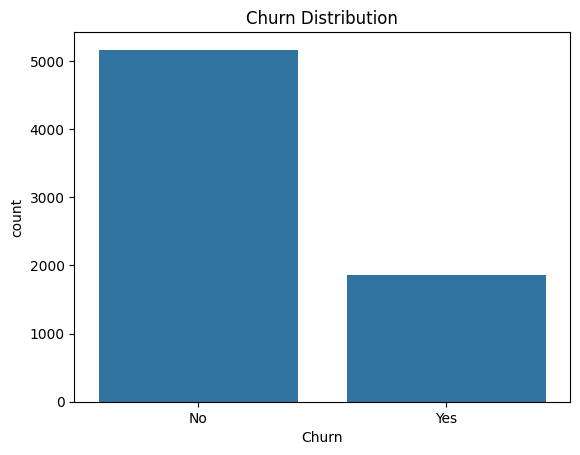

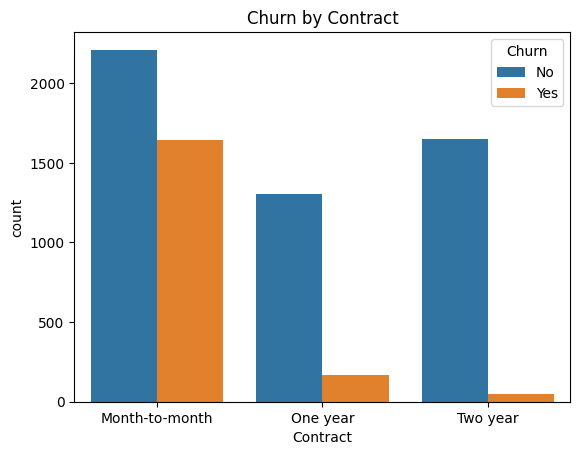

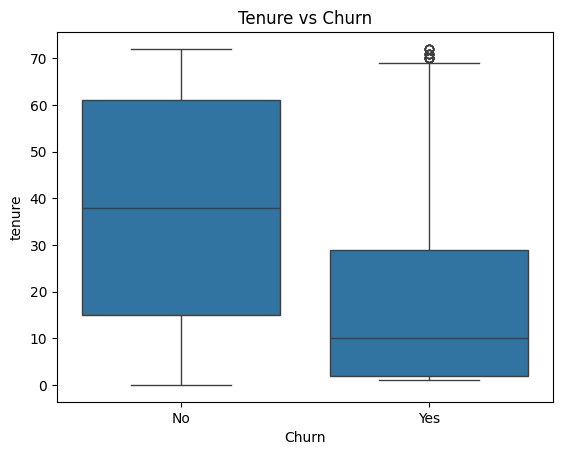

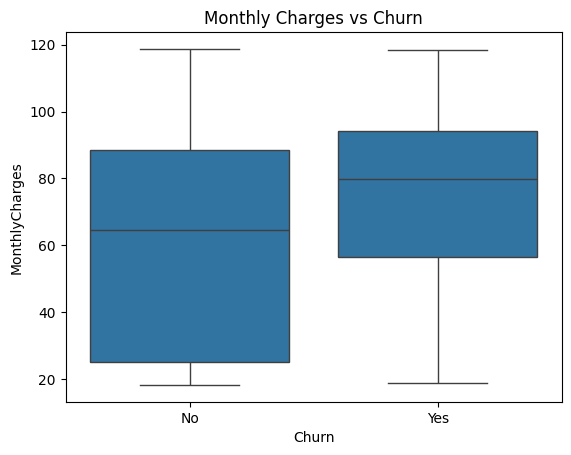

Contract
Month-to-month    42.642097
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64


In [8]:
sns.countplot(x="Churn", data=df)
plt.title("Churn Distribution")
plt.show()

sns.countplot(x="Contract", hue="Churn", data=df)
plt.title("Churn by Contract")
plt.show()

sns.boxplot(x="Churn", y="tenure", data=df)
plt.title("Tenure vs Churn")
plt.show()

sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.title("Monthly Charges vs Churn")
plt.show()

# Churn % by contract
print(df.groupby("Contract")["Churn"].apply(lambda x: (x == "Yes").mean() * 100))

In [9]:
# New feature: tenure in years
df["TenureYears"] = df["tenure"] / 12

# Target y: Yes = 1, No = 0
y = df["Churn"].map({"Yes": 1, "No": 0})

# Input X: everything except Churn, text columns turned into numbers
X = df.drop("Churn", axis=1)
X = pd.get_dummies(X, drop_first=True)

print("X shape:", X.shape)
print("y shape:", y.shape)
print(X.head())

X shape: (7021, 31)
y shape: (7021,)
   SeniorCitizen  tenure  MonthlyCharges  TotalCharges  TenureYears  \
0              0       1           29.85         29.85     0.083333   
1              0      34           56.95       1889.50     2.833333   
2              0       2           53.85        108.15     0.166667   
3              0      45           42.30       1840.75     3.750000   
4              0       2           70.70        151.65     0.166667   

   gender_Male  Partner_Yes  Dependents_Yes  PhoneService_Yes  \
0        False         True           False             False   
1         True        False           False              True   
2         True        False           False              True   
3         True        False           False             False   
4        False        False           False              True   

   MultipleLines_No phone service  ...  StreamingTV_No internet service  \
0                            True  ...                            Fals

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# Scale data for Logistic Regression
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Model 1
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_s, y_train)

# Model 2
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

print("Training done")

Training done


                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression     0.794      0.597   0.543     0.568
1        Random Forest     0.791      0.605   0.483     0.537
Logistic Regression Confusion Matrix:
[[924 129]
 [161 191]]


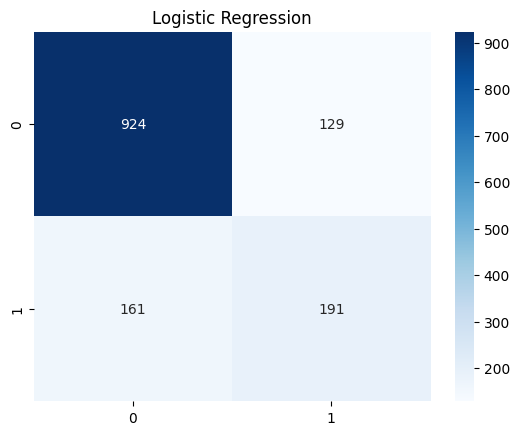

Random Forest Confusion Matrix:
[[942 111]
 [182 170]]


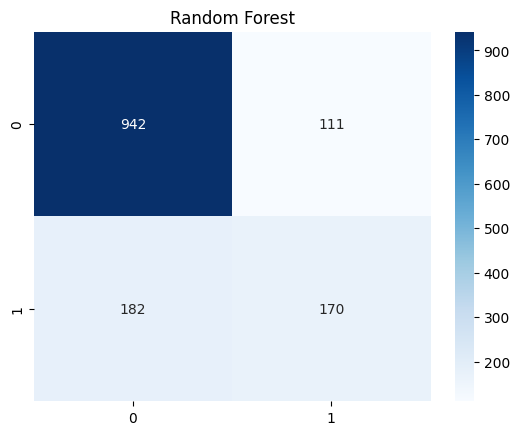

In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

lr_pred = lr.predict(X_test_s)
rf_pred = rf.predict(X_test)

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [accuracy_score(y_test, lr_pred), accuracy_score(y_test, rf_pred)],
    "Precision": [precision_score(y_test, lr_pred), precision_score(y_test, rf_pred)],
    "Recall": [recall_score(y_test, lr_pred), recall_score(y_test, rf_pred)],
    "F1-Score": [f1_score(y_test, lr_pred), f1_score(y_test, rf_pred)],
})
print(results.round(3))

print("Logistic Regression Confusion Matrix:")
print(confusion_matrix(y_test, lr_pred))
sns.heatmap(confusion_matrix(y_test, lr_pred), annot=True, fmt="d", cmap="Blues")
plt.title("Logistic Regression")
plt.show()

print("Random Forest Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))
sns.heatmap(confusion_matrix(y_test, rf_pred), annot=True, fmt="d", cmap="Blues")
plt.title("Random Forest")
plt.show()

# Compare the F1-Scores in the table and pick the better model
# for the report (in the next block, change 'model' if needed).

In [12]:
# Final model (Logistic Regression is used here; change if RF scored better)
model = lr
use_scaler = True

def predict_churn(customer):
    new = pd.DataFrame([customer])
    new["TenureYears"] = new["tenure"] / 12

    # Encode the same way as training data
    all_data = pd.concat([df.drop("Churn", axis=1), new])
    all_data = pd.get_dummies(all_data, drop_first=True)
    new_row = all_data.tail(1)[X.columns]

    if use_scaler:
        new_row = scaler.transform(new_row)

    result = model.predict(new_row)[0]
    return "Churn" if result == 1 else "No Churn"

customer1 = {"gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No",
    "tenure": 2, "PhoneService": "Yes", "MultipleLines": "No",
    "InternetService": "Fiber optic", "OnlineSecurity": "No", "OnlineBackup": "No",
    "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "Yes",
    "StreamingMovies": "Yes", "Contract": "Month-to-month", "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check", "MonthlyCharges": 95.5, "TotalCharges": 191.0}

customer2 = {"gender": "Male", "SeniorCitizen": 0, "Partner": "Yes", "Dependents": "Yes",
    "tenure": 60, "PhoneService": "Yes", "MultipleLines": "Yes",
    "InternetService": "DSL", "OnlineSecurity": "Yes", "OnlineBackup": "Yes",
    "DeviceProtection": "Yes", "TechSupport": "Yes", "StreamingTV": "No",
    "StreamingMovies": "No", "Contract": "Two year", "PaperlessBilling": "No",
    "PaymentMethod": "Bank transfer (automatic)", "MonthlyCharges": 65.0, "TotalCharges": 3900.0}

print("Customer 1:", predict_churn(customer1))
print("Customer 2:", predict_churn(customer2))

Customer 1: Churn
Customer 2: No Churn
